# 05 · Session regimes — does leadership migrate?

Lookahead-immune by construction: sessions are defined by the wall clock. We re-run the
bivariate discovery per session and test — moving-block bootstrap over days + Holm — whether
the cross's leadership changes across the day. Publishable either way; the main threat is
staleness (thin Tokyo hours for the EUR legs).

In [1]:
%load_ext autoreload
%autoreload 2
import datetime as dt, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from fxpd.config import TRIANGLES, OUTPUTS_DIR, ensure_dirs
from fxpd.data.processed import get_panel
from fxpd.calendar.sessions import label_sessions, SESSION_ORDER
from fxpd.econo import discovery as disc
from fxpd.inference import bootstrap as bs
ensure_dirs(); warnings.simplefilter("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Parameters + pre-registered hypotheses (before any result)

Priors: GG_cross ↑ in TOK (JPY-local info via the quoted cross); LDN+NY dollar/synth-dominated;
half-lives shortest in LDN+NY. Stability instead is a clean efficiency result. GG is primary;
statistic = nanmedian(A) − nanmedian(B), Holm across the family.

- H1: GG_cross(TOK) − GG_cross(LDN) > 0
- H2: GG_cross(TOK) − GG_cross(NY) > 0
- H3: GG_cross(LDN+NY) − GG_cross(TOK+LDN) ≠ 0
- H4: half-life(LDN+NY) − equal-weight edge ½·[HL(TOK)+HL(NY)] < 0, complete-case days, all
 sessions restricted to liquid hours 07–17 UTC
- H5 (secondary): IS-midpoint(TOK) − IS-midpoint(LDN) > 0 (expected weak — IS uninformative at 1s)

In [2]:
TRIANGLE = "majors"
START, END = dt.date(2025, 12, 15), dt.date(2026, 7, 20)
FC_START, FC_END = dt.date(2026, 5, 18), dt.date(2026, 6, 19)
K, LIQUID = 10, (7, 17)
SESSIONS = ["TOK", "TOK+LDN", "LDN", "LDN+NY", "NY"]
tri = TRIANGLES[TRIANGLE]
dates    = list(pd.bdate_range(START, END).date)
fc_dates = list(pd.bdate_range(FC_START, FC_END).date)
print(f"{tri} | {len(dates)} days | 1s primary, 250ms robustness | k={K}")

Triangle(name='majors', cross='EURJPY', leg1='EURUSD', leg2='USDJPY') | 156 days | 1s primary, 250ms robustness | k=10


## 1 · Session-calendar sanity — you can *see* the DST shift

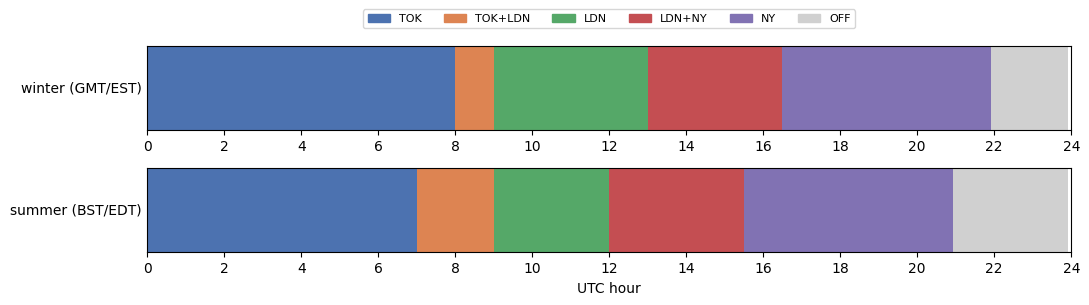

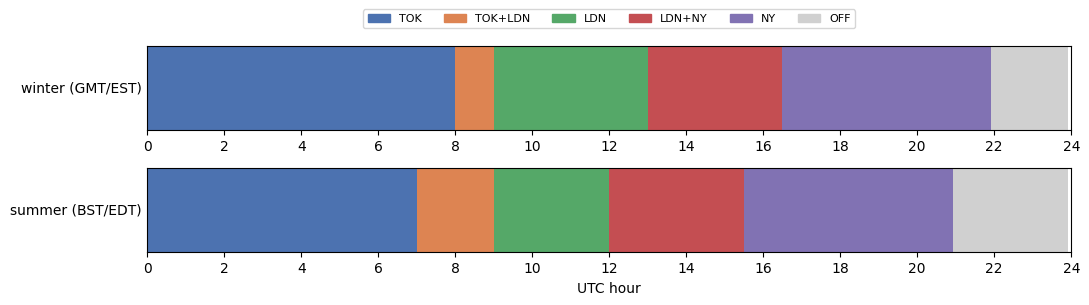

In [3]:
colors = {"TOK":"#4C72B0","TOK+LDN":"#DD8452","LDN":"#55A868","LDN+NY":"#C44E52",
          "NY":"#8172B3","OFF":"#D0D0D0"}
fig, axes = plt.subplots(2, 1, figsize=(11, 3.2))
for ax, (d, season) in zip(axes, [(dt.date(2026,1,15),"winter (GMT/EST)"),
                                   (dt.date(2026,7,15),"summer (BST/EDT)")]):
    idx = pd.date_range(pd.Timestamp(d, tz="UTC"), periods=24*12, freq="5min")
    lab = label_sessions(idx); hrs = (idx - idx[0]).total_seconds()/3600
    for i in range(len(idx)-1):
        ax.axvspan(hrs[i], hrs[i+1], color=colors[str(lab[i])], lw=0)
    ax.set_yticks([]); ax.set_ylabel(season, rotation=0, ha="right", va="center")
    ax.set_xlim(0,24); ax.set_xticks(range(0,25,2))
axes[-1].set_xlabel("UTC hour")
axes[0].legend(handles=[mpatches.Patch(color=c,label=l) for l,c in colors.items()],
               ncol=6, fontsize=8, loc="lower center", bbox_to_anchor=(0.5,1.15))
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"05_session_calendar.png", dpi=130); fig

## 2 · Staleness by session (the mechanical control)

In [4]:
def fresh_by_session(sample):
    rows = []
    for s in SESSIONS:
        acc = {leg: [] for leg in tri.legs}; syn = []
        for d in sample:
            try: p = get_panel(tri, d, "1s")
            except FileNotFoundError: continue
            w = p[np.asarray(label_sessions(p.index) == s)]
            if len(w) == 0: continue
            for leg in tri.legs: acc[leg].append(float((w[f"age_{leg}"] <= 1.0).mean()))
            syn.append(float(((w[f"age_{tri.leg1}"]<=1.0) & (w[f"age_{tri.leg2}"]<=1.0)).mean()))
        rows.append({"session": s, **{leg: np.mean(acc[leg]) for leg in tri.legs},
                     "synth(both)": np.mean(syn)})
    return pd.DataFrame(rows).set_index("session")
STALE = fresh_by_session(dates[::8])
STALE.round(3)

,EURJPY,EURUSD,USDJPY,synth(both)
session,,,,
TOK,0.594,0.302,0.385,0.188
TOK+LDN,0.732,0.478,0.522,0.336
LDN,0.623,0.393,0.394,0.238
LDN+NY,0.789,0.608,0.601,0.458
NY,0.551,0.375,0.372,0.234


## 3 · the table — discovery by session (1 s, full range)

In [5]:
res = {s: disc.fit_discovery_windows(tri, dates, "1s", K, session=s) for s in SESSIONS}
def row(s):
    a = disc.aggregate_discovery(res[s])
    return {"GG_cross": a.loc["cross","gg_median"],
            "GG [IQR]": f"[{a.loc['cross','gg_q25']:.2f}, {a.loc['cross','gg_q75']:.2f}]",
            "IS [lo, hi]": f"[{a.loc['cross','is_lo']:.2f}, {a.loc['cross','is_hi']:.2f}]",
            "HL_proxy_s": round(a.attrs["half_life_median"], 1),
            "HL_dynamic_s": round(a.attrs["half_life_dyn_median"], 1),
            "n": a.attrs["n_valid"]}
THE = pd.DataFrame({s: row(s) for s in SESSIONS}).T
THE

,GG_cross,GG [IQR],"IS [lo, hi]",HL_proxy_s,HL_dynamic_s,n
TOK,0.6301,"[0.47, 0.74]","[0.05, 0.98]",3,6.4,69
TOK+LDN,0.6312,"[0.50, 0.76]","[0.06, 0.98]",3.1,7.1,142
LDN,0.6779,"[0.58, 0.77]","[0.09, 0.98]",3.8,8.3,151
LDN+NY,0.6508,"[0.53, 0.75]","[0.07, 0.98]",2.9,7.2,145
NY,0.6676,"[0.53, 0.82]","[0.10, 0.97]",3.1,7,142


## 4 · the figure — GG_cross by session with block-bootstrap CIs

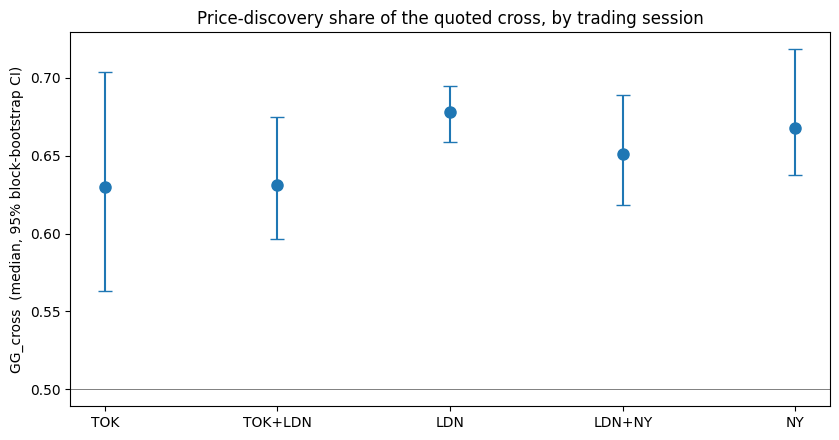

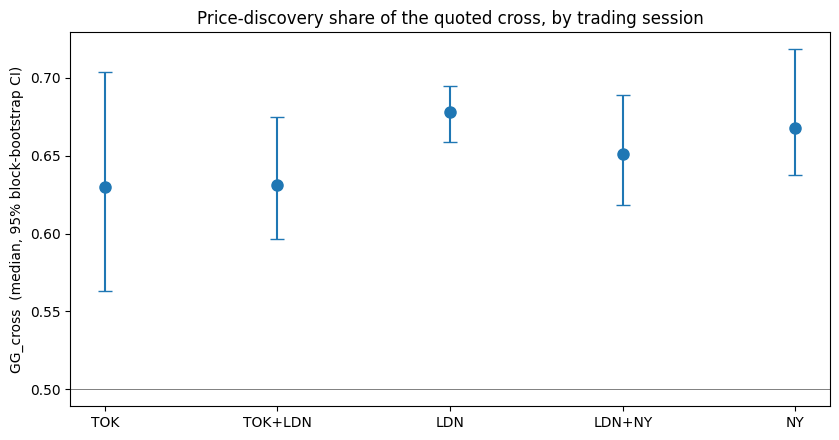

In [6]:
wide_gg = bs.metric_by_day(res, "gg_cross")
pts, los, his = [], [], []
for s in SESSIONS:
    pt, ci = bs.session_median_ci(wide_gg, s, block=5, B=2000, seed=0)
    pts.append(pt); los.append(ci[0]); his.append(ci[1])
pts = np.array(pts)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.errorbar(range(len(SESSIONS)), pts, yerr=[pts-np.array(los), np.array(his)-pts],
            fmt="o", ms=8, capsize=5, color="tab:blue")
ax.axhline(0.5, color="k", lw=0.7, alpha=0.5)
ax.set_xticks(range(len(SESSIONS))); ax.set_xticklabels(SESSIONS)
ax.set_ylabel("GG_cross  (median, 95% block-bootstrap CI)")
ax.set_title("Price-discovery share of the quoted cross, by trading session")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"05_money_plot.png", dpi=130); fig

## 5 · Hypothesis tests (H1–H5, block bootstrap + Holm)

In [7]:
wide_hl = bs.metric_by_day(res, "half_life_dyn_s")
res_mid = {s: df.assign(is_mid=(df.is_cross_lo + df.is_cross_hi)/2) for s, df in res.items()}
wide_mid = bs.metric_by_day(res_mid, "is_mid")
HYPS = [
    ("H1 GG TOK>LDN",        bs.diff_medians("TOK","LDN"),          wide_gg,  "greater"),
    ("H2 GG TOK>NY",         bs.diff_medians("TOK","NY"),           wide_gg,  "greater"),
    ("H3 GG LDN+NY!=TOK+LDN", bs.diff_medians("LDN+NY","TOK+LDN"),  wide_gg,  "two-sided"),
    ("H4 HL LDN+NY<{TOK,NY} (eq-wt, complete-case)", bs.diff_vs_equal_edge("LDN+NY",["TOK","NY"]), wide_hl, "less"),
    ("H5 IS-mid TOK>LDN (2ry)", bs.diff_medians("TOK","LDN"),       wide_mid, "greater"),
]
rows = []
for name, fn, wide, alt in HYPS:
    stat, ci, dist = bs.block_bootstrap(wide, fn, block=5, B=2000, seed=0)
    rows.append({"hypothesis": name, "stat": stat, "ci_lo": ci[0], "ci_hi": ci[1],
                 "p_raw": bs.p_from_dist(dist, alt)})
H = pd.DataFrame(rows)
H["p_holm"] = bs.holm(H["p_raw"].tolist())
H["verdict"] = np.where(H["p_holm"] < 0.05, "reject H0", "n.s.")
H["p_raw"]=H["p_raw"].map(lambda v: "<0.0005" if v<0.0005 else f"{v:.4f}")
H.set_index("hypothesis").round(4)

,stat,ci_lo,ci_hi,p_raw,p_holm,verdict
hypothesis,,,,,,
H1 GG TOK>LDN,-0.0478,-0.1169,0.0243,0.9270,1,n.s.
H2 GG TOK>NY,-0.0375,-0.1223,0.0455,0.8435,1,n.s.
H3 GG LDN+NY!=TOK+LDN,0.0195,-0.0239,0.0674,0.3120,1,n.s.
"H4 HL LDN+NY<{TOK,NY} (eq-wt, complete-case)",1.474,0.6226,2.373,0.9980,1,n.s.
H5 IS-mid TOK>LDN (2ry),-0.0168,-0.0243,-0.007,0.9995,1,n.s.


## 6 · Robustness — is the pattern information or staleness?

In [8]:
res_sf = {s: disc.fit_discovery_windows(tri, dates, "1s", K, session=s, stale_filter=True)
          for s in SESSIONS}
def gg(r): return disc.aggregate_discovery(r).loc["cross","gg_median"]
STALE_CMP = pd.DataFrame({
    "GG all bars":   [gg(res[s])    for s in SESSIONS],
    "GG fresh only": [gg(res_sf[s]) for s in SESSIONS],
}, index=SESSIONS)
STALE_CMP["delta"] = STALE_CMP["GG fresh only"] - STALE_CMP["GG all bars"]
STALE_CMP["synth_fresh_share"] = STALE["synth(both)"]
def hl(r): return disc.aggregate_discovery(r).attrs["half_life_dyn_median"]
STALE_CMP["HL all"]   = [hl(res[s])    for s in SESSIONS]
STALE_CMP["HL fresh"] = [hl(res_sf[s]) for s in SESSIONS]
STALE_CMP.round(3)

,GG all bars,GG fresh only,delta,synth_fresh_share,HL all,HL fresh
TOK,0.63,0.598,-0.033,0.188,6.435,4.82
TOK+LDN,0.631,0.572,-0.059,0.336,7.086,5.687
LDN,0.678,0.626,-0.052,0.238,8.293,6.09
LDN+NY,0.651,0.607,-0.044,0.458,7.186,5.744
NY,0.668,0.586,-0.082,0.234,7.043,5.054


In [9]:
res_1s_fc  = {s: disc.fit_discovery_windows(tri, fc_dates, "1s",    K, session=s) for s in SESSIONS}
res_250_fc = {s: disc.fit_discovery_windows(tri, fc_dates, "250ms", K, session=s) for s in SESSIONS}
FREQ_CMP = pd.DataFrame({
    "GG 1s (1mo)":    [gg(res_1s_fc[s])  for s in SESSIONS],
    "GG 250ms (1mo)": [gg(res_250_fc[s]) for s in SESSIONS],
}, index=SESSIONS)
FREQ_CMP.round(3)

,GG 1s (1mo),GG 250ms (1mo)
TOK,NaN,NaN
TOK+LDN,0.631,0.614
LDN,0.654,0.624
LDN+NY,0.634,0.604
NY,0.638,0.624


## Takeaway

On the 1 s grid the leadership *share* doesn't move across sessions, and the earlier *speed* effect
is withdrawn. The cross carries 0.63–0.68 in every session (all block-bootstrap CIs overlap, all
above 0.5); H1–H5 are n.s. (raw p 0.93 / 0.84 / 0.31 / 1.00 / 1.00; Holm = 1 for all). There is
no Tokyo elevation — TOK (0.630) is the lowest, with TOK+LDN (0.631). Fresh-only filtering lowers
every session by 0.03–0.08 and leaves no ordering (0.57–0.63).

H4 (speed) is n.s. once every session uses liquid hours (07–17 UTC): the old "LDN+NY fastest" was
a time-support + pooling artifact (TOK had been measured on overnight 00–07 UTC). Dynamic
half-lives 6.4–8.3 s; H4 = +1.47 s (LDN+NY *slower*), Holm 1 — withdrawn. H5 n.s., as expected.

Two limits on "no migration" (07): (1) **time support** — inside 07–17 UTC, TOK is 07–08 UTC in
Dec–Mar only (no TOK windows Apr–Jul, hence NaN in the one-month table) and NY is the last 30–90
min before 17:00, so this describes the London trading day; (2) **clock** — in refresh time the
cross's share rises through the day (TOK 0.48 → NY 0.61) and H3 has p 0.005 (Holm 0.025 within
the refresh family, 0.05 across both clocks — borderline), with TOK
*below* LDN/NY, opposite to H1/H2. Neither clock supports the pre-registered migration, but the
null is not robust to the clock, and no session pair is TOST-equivalent within ±0.05.
Aggregator quotes, one venue.